# Membangun Gugus Bintang dengan Model Plummer

Nama: T. M. Aldine Al Kautsar

NIM: 20926005

## Generate gugus dengan N = 1000.

### Menyusun posisi: inverse transform sampling

Ambil $X_1 \thicksim  U(0,1)$, lalu selesaikan $X_1 = M(<r)/M$:

$$r = \frac{a}{\sqrt{X_1^{-2/3} - 1}}$$

In [340]:
import numpy as np

def r(X, a=1.0):
    return a / np.sqrt(X**(-2/3) - 1)

Arah posisi haruslah **isotropik**. Ambil $\cos{\theta} \thicksim U(-1, 1)$ dan $\phi \thicksim U(0, 2\pi)$, maka

$$x = r \sin{\theta} \cos{\phi}, \quad y = r \sin{\theta} \sin{\phi}, \quad z = r \cos{\theta}$$

In [341]:
def isotropik(r):
    cos_theta = np.random.uniform(-1, 1)
    phi = np.random.uniform(0, 2*np.pi)
    sin_theta = np.sqrt(1 - cos_theta**2)

    x = r * sin_theta * np.cos(phi)
    y = r * sin_theta * np.sin(phi)
    z = r * cos_theta

    return x, y, z  

In [342]:
N = 1000
rmax = 20

r_list = []
x = []
y = []
z = []

while len(r_list) < N:
    X1 = np.random.uniform(0, 1)
    rn = r(X1)

    if rn <= rmax:
        xn, yn, zn = isotropik(rn)
        
        r_list.append(rn)
        x.append(xn)
        y.append(yn)
        z.append(zn)

### Menyusun kecepatan: rejection sampling

Untuk model isotropik, kecepatan dinyatakan sebagai $v = q v_{esc}(r)$ dengan $0 \lt q \lt 1$. Aarseth, Hénon & Wielen (1974) menunjukkan bahwa $q$ terdistribusi menurut

$$g(q) = q^2 (1 - q^2)^{7/2}$$

In [343]:
def g(q):
    return q**2 * (1 - q**2)**(7/2)

$$v_{esc}(r) = \sqrt{2GM_0} (r^2 + a^2)^{-1/4}$$

In [344]:
def v_esc(r, a=1.0, M=1.0, G=1.0):
    return np.sqrt(2*G*M) * (r**2 + a**2)**(-1/4)

CDF dari $g(q)$ tidak dapat dengan mudah dibalikkan secara analitik, sehingga kita gunakan saja
metode *rejection sampling* (von Neumann):

1. Ambil $x \thicksim U(0, 1)$ dan $y \thicksim U(0, 0.1)$
2. Jika $y < x^2(1 - x^2)^{7/2}$, terima $q=x$. Jika tidak, ulangi dari langkah 1.

Berdasarkan paper Aarseth, Hénon & Wielen (1974), batas atas $g(q)$ selalu kurang dari $0.1$.

In [345]:
q = []

while len(q) < N:
    xn = np.random.uniform(0, 1)
    yn = np.random.uniform(0, 0.1)

    if yn < g(xn):
        q.append(xn)

$$v = q v_{esc}(r)$$

In [346]:
r_list = np.array(r_list)
q = np.array(q)

v = q * v_esc(r_list)

Arah kecepatan juga bersifat isotropik (generate kembali $\cos{\theta}$ dan $\phi$ baru, yang tidak bergantung
pada arah posisi).

In [347]:
vx, vy, vz = isotropik(v)

Terakhir, pindahkan sistem ke kerangka acuan pusat massa: kurangi posisi dan
kecepatan pusat massa dari semua partikel.

In [348]:
x = np.array(x) - np.average(x)
y = np.array(y) - np.average(y)
z = np.array(z) - np.average(z)

vx = np.array(vx) - np.average(vx)
vy = np.array(vy) - np.average(vy)
vz = np.array(vz) - np.average(vz)

r = np.sqrt(x**2 + y**2 + z**2)
v = np.sqrt(vx**2 + vy**2 + vz**2)

## Proyeksi $x–y$ dan $x–z$

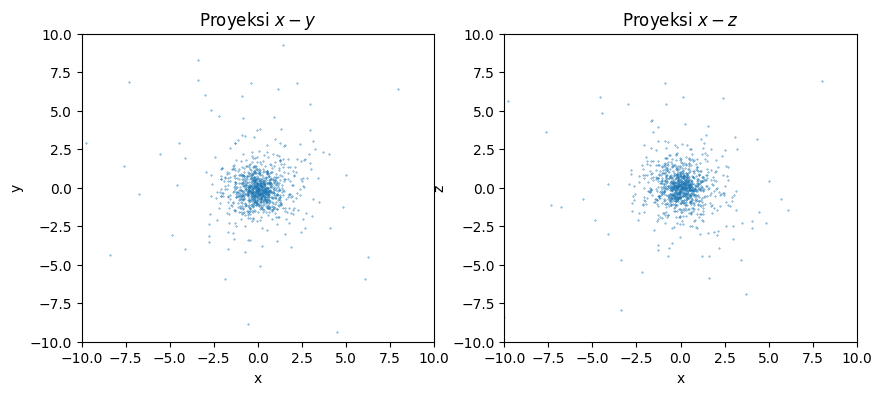

In [349]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax[0].scatter(x, y, s=0.1)
ax[0].set_title('Proyeksi $x-y$')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_xlim(-10, 10)
ax[0].set_ylim(-10, 10)

ax[1].scatter(x, z, s=0.1)
ax[1].set_title('Proyeksi $x-z$')
ax[1].set_xlabel('x')
ax[1].set_ylabel('z')
ax[1].set_xlim(-10, 10)
ax[1].set_ylim(-10, 10)

plt.show()

## Diagram ruang fase ($r$ terhadap $|v|$). Bandingkan plot $r$ terhadap $|v|$ dengan escape velocity.

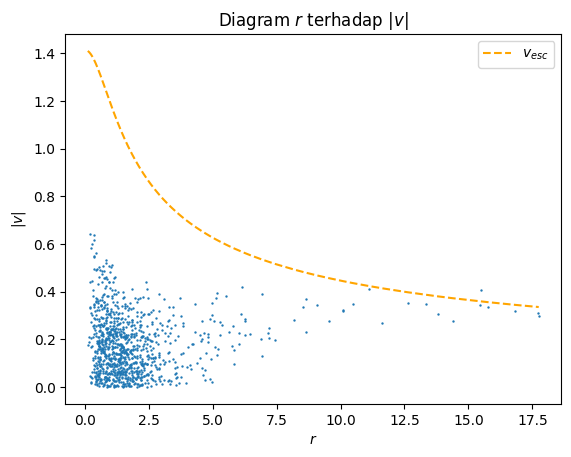

In [350]:
plt.scatter(r, np.abs(v), s=0.5)
plt.plot(np.sort(r), v_esc(np.sort(r)), linestyle='--', color='orange', label='$v_{esc}$')
plt.xlabel('$r$')
plt.ylabel('$|v|$')
plt.title('Diagram $r$ terhadap $|v|$')
plt.legend()
plt.show()